In [10]:
import pandas as pd
import numpy as np
from pathlib import Path

from sympy.sets.sets import is_function_invertible_in_set

source_path  = Path.cwd().parent / "资料-pd"
data_path = source_path / "employees.csv"

df = pd.read_csv(data_path)

In [12]:
df.head(5)

,employee_id,first_name,last_name,email,phone_number,job_id,salary,commission_pct,manager_id,department_id
0,100,Steven,King,SKING,515.123.4567,AD_PRES,24000,NaN,NaN,90.0
1,101,N_ann,Kochhar,NKOCHHAR,515.123.4568,AD_VP,17000,NaN,100.0,90.0
2,102,Lex,De Haan,LDEHAAN,515.123.4569,AD_VP,17000,NaN,100.0,90.0
3,103,Alexander,Hunold,AHUNOLD,590.423.4567,IT_PROG,9000,NaN,102.0,60.0
4,104,Bruce,Ernst,BERNST,590.423.4568,IT_PROG,6000,NaN,103.0,60.0


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 107 entries, 0 to 106
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   employee_id     107 non-null    int64  
 1   first_name      107 non-null    str    
 2   last_name       107 non-null    str    
 3   email           107 non-null    str    
 4   phone_number    107 non-null    str    
 5   job_id          107 non-null    str    
 6   salary          107 non-null    int64  
 7   commission_pct  35 non-null     float64
 8   manager_id      106 non-null    float64
 9   department_id   106 non-null    float64
dtypes: float64(3), int64(2), str(5)
memory usage: 8.5 KB


In [14]:
print(df.describe())

       employee_id        salary  commission_pct  manager_id  department_id
count   107.000000    107.000000       35.000000  106.000000     106.000000
mean    153.000000   6564.485981        0.222857  124.764151      63.207547
std      31.032241   4237.662500        0.085184   20.315395      20.910110
min     100.000000   2100.000000        0.100000  100.000000      10.000000
25%     126.500000   3050.000000        0.150000  108.000000      50.000000
50%     153.000000   6200.000000        0.200000  122.000000      50.000000
75%     179.500000   8900.000000        0.300000  145.000000      80.000000
max     206.000000  24000.000000        0.400000  205.000000     110.000000


In [16]:
df.shape

(107, 10)

In [20]:
# 找出薪资最高 最低的人
df.nlargest(1, "salary")
#df.nsmallest(1, "salary")


,employee_id,first_name,last_name,email,phone_number,job_id,salary,commission_pct,manager_id,department_id
0,100,Steven,King,SKING,515.123.4567,AD_PRES,24000,NaN,NaN,90.0


In [21]:
df.loc[df["salary"] == df["salary"].max()]


,employee_id,first_name,last_name,email,phone_number,job_id,salary,commission_pct,manager_id,department_id
0,100,Steven,King,SKING,515.123.4567,AD_PRES,24000,NaN,NaN,90.0
105,205,Shelley,Higgins,SHIGGINS,515.123.8080,AC_MGR,24000,NaN,101.0,110.0


In [22]:
df.loc[df["salary"] == df["salary"].min()]

,employee_id,first_name,last_name,email,phone_number,job_id,salary,commission_pct,manager_id,department_id
15,115,Alexander,Khoo,AKHOO,515.127.4562,PU_CLERK,2100,NaN,114.0,30.0
32,132,TJ,Olson,TJOLSON,650.124.8234,ST_CLERK,2100,NaN,121.0,50.0


In [24]:
# 使用排序找到薪资最低的员工

In [26]:
df.sort_values(by="salary", ascending=True).head(1)


,employee_id,first_name,last_name,email,phone_number,job_id,salary,commission_pct,manager_id,department_id
32,132,TJ,Olson,TJOLSON,650.124.8234,ST_CLERK,2100,NaN,121.0,50.0


In [30]:
# 查看所有部门的id
df.loc[:,"department_id"].unique()


array([ 90.,  60., 100.,  30.,  50.,  80.,  nan,  10.,  20.,  40.,  70.,
       110.])

In [31]:
df['department_id'].unique()


array([ 90.,  60., 100.,  30.,  50.,  80.,  nan,  10.,  20.,  40.,  70.,
       110.])

In [33]:
# 查看每个部门的员工数
df.groupby("department_id")["employee_id"].count().rename("employee_count")

department_id
10.0      1
20.0      2
30.0      6
40.0      1
50.0     45
60.0      5
70.0      1
80.0     34
90.0      3
100.0     6
110.0     2
Name: employee_count, dtype: int64

<Axes: xlabel='department_id'>

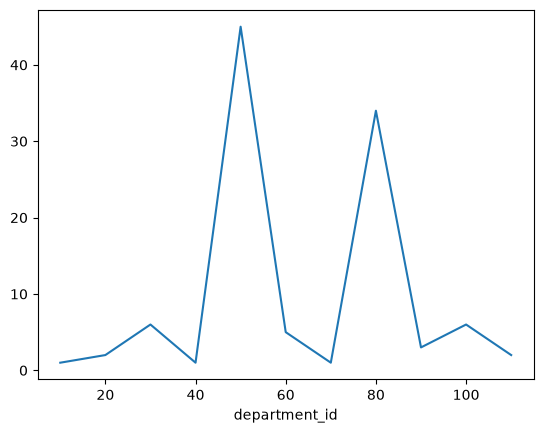

In [34]:
# 绘图
df.groupby("department_id")["employee_id"].count().rename("employee_count").plot()


In [35]:
# 薪资分布

In [39]:
df["salary"].min()
df["salary"].max()
df["salary"].median()





np.float64(6200.0)

In [40]:
# 平均工资最高的部门
df.groupby("department_id")["salary"].mean().nlargest(1)


department_id
90.0    19333.333333
Name: salary, dtype: float64

In [43]:
# pandas数据组合函数
# concat
s1 = pd.Series([1,2,3,4],index=[0,1,2,3])
s2 = pd.Series([5,6,7,8],index=[4,5,6,7])

pd.concat([s1,s2])



0    1
1    2
2    3
3    4
4    5
5    6
6    7
7    8
dtype: int64

In [44]:
pd.concat([s1,s2],axis=1)


,0,1
0,1.0,NaN
1,2.0,NaN
2,3.0,NaN
3,4.0,NaN
4,NaN,5.0
5,NaN,6.0
6,NaN,7.0
7,NaN,8.0


In [65]:
df1 = pd.DataFrame(np.random.randn(3, 4), columns=['A', 'B', 'C', 'D'],index=[0,1,2])
df1
s1 = pd.Series([1,2,3],index=[0,1,2])


In [67]:
pd.concat([df1,s1],axis=0)

,A,B,C,D,0
0,1.376153,2.913580,-0.428933,1.245455,NaN
1,0.470265,0.835485,1.053091,-0.866403,NaN
2,-0.074150,0.631675,0.001651,1.121001,NaN
0,NaN,NaN,NaN,NaN,1.0
1,NaN,NaN,NaN,NaN,2.0
2,NaN,NaN,NaN,NaN,3.0


In [68]:
pd.concat([df1,s1],axis=1)

,A,B,C,D,0
0,1.376153,2.913580,-0.428933,1.245455,1
1,0.470265,0.835485,1.053091,-0.866403,2
2,-0.074150,0.631675,0.001651,1.121001,3


In [ ]:
# dataframe 和 dataframe 拼接

In [70]:
df2 = pd.DataFrame(np.random.randn(3, 4), columns=['A', 'B', 'C', 'D'],index=[0,1,2])

pd.concat([df1,df2],axis=0,ignore_index=True)

,A,B,C,D
0,1.376153,2.913580,-0.428933,1.245455
1,0.470265,0.835485,1.053091,-0.866403
2,-0.074150,0.631675,0.001651,1.121001
3,0.806399,0.310177,-0.707819,-0.391811
4,-0.852968,-0.746762,-0.510814,0.495351
5,-0.158421,0.530771,-1.503114,0.625649


In [71]:
## merge  一对一  多对一 多对多

In [78]:
df1 = pd.DataFrame({"employee": ["Bob", "Jake", "Lisa", "Sue"], "group": ["Accounting", "Engineering", "Engineering", "HR"]})

In [79]:
df2 = pd.DataFrame({"employee": ["Lisa", "Bob", "Jake", "Sue"], "hire_date": [2004, 2008, 2012, 2014]})
pd.merge(df1,df2,on="employee")

,employee,group,hire_date
0,Bob,Accounting,2008
1,Jake,Engineering,2012
2,Lisa,Engineering,2004
3,Sue,HR,2014


In [86]:
# 多对一
df1 = pd.DataFrame({"employee": ["Bob", "Jake", "Lisa", "Sue"], "group": ["Accounting", "Engineering", "Engineering", "HR"]})
df2 = pd.DataFrame({"group": ["Accounting", "Engineering", "HR"], "supervisor": ["Carly", "Guido", "Steve"]})
pd.merge(df1,df2,on="group")


,employee,group,supervisor
0,Bob,Accounting,Carly
1,Jake,Engineering,Guido
2,Lisa,Engineering,Guido
3,Sue,HR,Steve


In [87]:
df1 = pd.DataFrame({"employee": ["Bob", "Jake", "Lisa", "Sue"], "group": ["Accounting", "Engineering", "Engineering", "HR"]})
df2 = pd.DataFrame({"group": ["Accounting", "Accounting", "Engineering", "Engineering", "HR", "HR"],"skills": ["math", "spreadsheets", "coding", "linux", "spreadsheets", "organization"],})

In [88]:
df3 = pd.merge(df1, df2)

In [89]:
df3

,employee,group,skills
0,Bob,Accounting,math
1,Bob,Accounting,spreadsheets
2,Jake,Engineering,coding
3,Jake,Engineering,linux
4,Lisa,Engineering,coding
5,Lisa,Engineering,linux
6,Sue,HR,spreadsheets
7,Sue,HR,organization
